In [2]:
# Instalar o pacote watermark 

!pip install -q -U watermark 

In [3]:
# Importação da biblioteca para manipulação de dados em tabelas 
import pandas as pd 
# Importação da biblioteca NumPy para operações matemáticas e arrays 
import numpy as np 
# Importação da biblioteca Matplotlib para a geração de gráficos 
import matplotlib.pyplot as plt
# Importação da biblioteca Seaborn para a visualização de estatística de dados 
import seaborn as sns 
# Importação  da biblioteca random  para a geração de números aleatórios 
import random 
# Importação das classes datetime e timedelta para manipulação de datas e intervalos de tempo
from datetime import datetime, timedelta 
# Comando mágico do Jupyter Notebook que permite exibir gráficos diretamente no notebook 
%matplotlib inline

%reload_ext watermark
%watermark -a "Data Science Academy" 
%watermark --iversions
# Para instalar uma versão específica de um pacote, podemos fazer assim (por exemplo): 
!pip install -q pandas==2.3.1 

Author: Data Science Academy

matplotlib: 3.10.0
numpy     : 2.1.3
pandas    : 2.3.1
seaborn   : 0.13.2



----

In [4]:
# Definição para gerar dados fictícios de vendas 
def dsa_gera_dados_ficticios(num_registros=600):
    """Gera um DataFrame do Pandas com dados de vendas fictícios."""
    # Mensagem inicial indicando a quantidade de registros a serem gerados 
    print(f"\nIniciando a geração de {num_registros} registros de vendas...")
    #Dicionário com produtos, suas categorias e preços 
    produtos = {
        'Laptop Gamer': {'categoria': 'Eletrônicos', 'preco': 7500.00},
        'Mouse Vertical': {'categoria': 'Acessórios', 'preco': 250.00},
        'Teclado Mecânico': {'categoria': 'Acessórios', 'preco': 550.00},
        'Monitor Ultrawide': {'categoria': 'Eletrônicos', 'preco': 2800.00},
        'Cadeira Gamer': {'categoria': 'Móveis', 'preco': 1200.00},
        'Headset 7.1': {'categoria': 'Acessórios', 'preco': 800.00},
        'Placa de Vídeo': {'categoria': 'Hardware', 'preco': 4500.00},
        'SSD 1TB': {'categoria': 'Hardware', 'preco': 600.00}
    }
    # Cria uma lista apenas com nomes dos produtos 
    lista_produtos = list(produtos.keys())
    # Dicionário apenas com os nomes das cidades
    cidades_estados ={
        'São Paulo':'SP',
        'Rio de Janeiro':'RJ',
        'Belo Horizonte':'MG',
        'Porto Alegre':'RS',
        'Salvador':'BA', 
        'Curitiba':'PR',
        'Fortaleza':'CE'
    }
    #Cria uma lista apenas com os nomes das cidades 
    lista_cidades = list(cidades_estados.keys())
    # Lista de que armazenará os registrod de venda 
    dados_vendas = []
    # Define a data inicial dos pedidos 
    data_inicial = datetime(2026,1,1)
    # Loop oara gerar um registro de vendas 
    for i in range(num_registros): 
        # Seleciona aleatoriamente um produto 
        produto_nome = random.choice(lista_produtos)
        # Seleciona aleatoriamente uma cidade 
        cidade = random.choice(lista_cidades)
        # Gera uma quantidade de produtos vendidos entre 1 e 7 
        quantidade = np.random.randint(1,8)
        # Calvula a data do pedido a partir da data inicial 
        data_pedido = data_inicial + timedelta(days = int(i/5), hours = random.randint(0,23))
        # Se o produto for Mouse ou Teclado, aplicar o desconto aleatório de 10% 
        if produto_nome in ['Mouse Vertcal', 'Teclado Mecânico']: 
            preco_unitário = produtos [produto_nome]['preco'] * np.random.uniform(0.9,1.0)
        else: 
            preco_unitario = produtos [produto_nome]['preco']
        # Adicionando um registro de venda na lista 
        dados_vendas.append({
            'ID_Pedido': 1000 + i,
            'Data_Pedido': data_pedido,
            'Nome_Produto': produto_nome,
            'Categoria': produtos[produto_nome]['categoria'],
            'Preco_Unitario': round(preco_unitario, 2),
            'Quantidade': quantidade,
            'ID_Cliente': np.random.randint(100, 150),
            'Cidade': cidade,
            'Estado': cidades_estados[cidade]
        })
    
    # Mensagem final indicando que a geração terminou
    print("Geração de dados concluída.\n")

    # Retorna os dados no formato de DataFrame
    return pd.DataFrame(dados_vendas)
    

___

In [5]:
# Gera dadas chamando a função da célula anterior 
df_vendas = dsa_gera_dados_ficticios(500)


Iniciando a geração de 500 registros de vendas...
Geração de dados concluída.



In [ ]:
type(df_vendas)

In [ ]:
# Shape 
df_vendas.shape


In [ ]:
# Exibe as 5 primeiras linhas do DataFrame
df_vendas.head()

In [ ]:
# Exibe as 5 últimas linhas do DataFrame
df_vendas.tail()

In [ ]:
# Exibe informações gerais sobre o DataFrame (tipos de dados, valores não nulos)
df_vendas.info()

In [ ]:
# Resumo estatístico
df_vendas.describe()

In [ ]:
# Tipos de dados
df_vendas.dtypes

___

In [6]:
# Se a coluna 'Data_Pedido' não estiver como tipo datetime, precisamos fazer a conversão explícita  
# A coluna pode ser usada para análise atemporal
df_vendas['Data_Pedido'] = pd.to_datetime(df_vendas['Data_Pedido'])

In [7]:
# Engenharia de atributos 
# Criando uma coluna de 'Faturanmento' (preço x quantidade)
df_vendas['Faturamento'] = df_vendas['Preco_Unitario'] * df_vendas['Quantidade']

In [8]:
# Engenharia de atributos
# Usando uma função lambda para criar uma coluna de status de entrega
df_vendas['Status_Entrega'] = df_vendas['Estado'].apply(lambda estado: 'Rápida' if estado in ['SP', 'RJ', 'MG'] else 'Normal')

In [9]:
# Exibe informações gerais sobre o DataFrame (Tipos de dados, valores não nulos)
df_vendas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   ID_Pedido       500 non-null    int64         
 1   Data_Pedido     500 non-null    datetime64[ns]
 2   Nome_Produto    500 non-null    object        
 3   Categoria       500 non-null    object        
 4   Preco_Unitario  500 non-null    float64       
 5   Quantidade      500 non-null    int64         
 6   ID_Cliente      500 non-null    int64         
 7   Cidade          500 non-null    object        
 8   Estado          500 non-null    object        
 9   Faturamento     500 non-null    float64       
 10  Status_Entrega  500 non-null    object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(5)
memory usage: 43.1+ KB


In [10]:
# Exibe as 5 primeiras linhas novamente para verificar as nvas colunas 
df_vendas.head(10)

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado,Faturamento,Status_Entrega
0,1000,2026-01-01 02:00:00,Monitor Ultrawide,Eletrônicos,2800.0,1,102,Porto Alegre,RS,2800.0,Normal
1,1001,2026-01-01 13:00:00,Laptop Gamer,Eletrônicos,7500.0,4,104,São Paulo,SP,30000.0,Rápida
2,1002,2026-01-01 07:00:00,Monitor Ultrawide,Eletrônicos,2800.0,6,128,Rio de Janeiro,RJ,16800.0,Rápida
3,1003,2026-01-01 16:00:00,Placa de Vídeo,Hardware,4500.0,6,117,Belo Horizonte,MG,27000.0,Rápida
4,1004,2026-01-01 23:00:00,SSD 1TB,Hardware,600.0,5,120,Curitiba,PR,3000.0,Normal
5,1005,2026-01-02 00:00:00,SSD 1TB,Hardware,600.0,1,116,Salvador,BA,600.0,Normal
6,1006,2026-01-02 00:00:00,Cadeira Gamer,Móveis,1200.0,3,139,Curitiba,PR,3600.0,Normal
7,1007,2026-01-02 15:00:00,Headset 7.1,Acessórios,800.0,6,148,Salvador,BA,4800.0,Normal
8,1008,2026-01-02 08:00:00,Cadeira Gamer,Móveis,1200.0,4,105,Salvador,BA,4800.0,Normal
9,1009,2026-01-02 04:00:00,Headset 7.1,Acessórios,800.0,2,134,Curitiba,PR,1600.0,Normal


___

In [14]:
# Agrupa por nome do produto, soma a quantidade e ordena para encontrar os mais vendidos
top_10_produtos = df_vendas.groupby('Nome_Produto')['Quantidade'].sum().sort_values(ascending = False).head(10)

Nome_Produto
Headset 7.1          275
Laptop Gamer         264
SSD 1TB              258
Mouse Vertical       254
Monitor Ultrawide    243
Cadeira Gamer        234
Placa de Vídeo       217
Teclado Mecânico     212
Name: Quantidade, dtype: int64

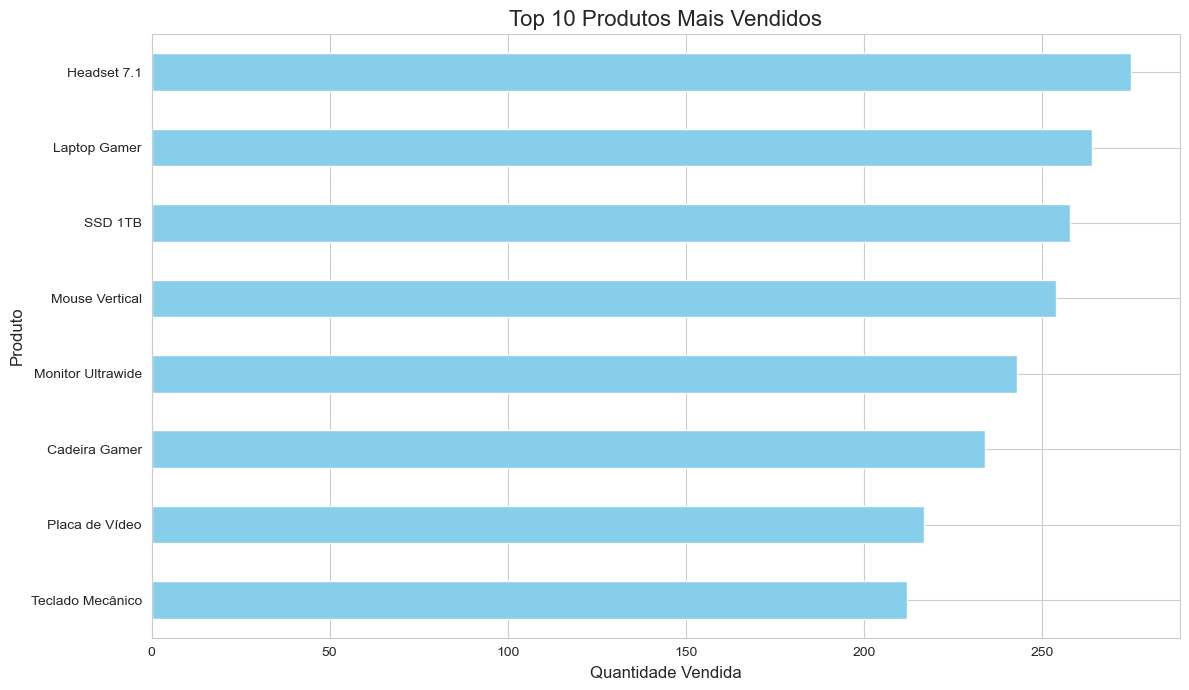

In [31]:
# Define um estilo para os gráficos 
sns.set_style("whitegrid")

# Cria a figura e os eixos 
plt.figure( figsize=(12, 7))

# Cria o gráfico de barras horizontais 
top_10_produtos.sort_values(ascending = True).plot(kind = 'barh', color = 'skyblue')

# Adiciona títulos e labels
plt.title('Top 10 Produtos Mais Vendidos', fontsize = 16)
plt.xlabel('Quantidade Vendida', fontsize = 12)
plt.ylabel('Produto', fontsize = 12)

# Exibe o gráfico 
plt.tight_layout()
plt.show()
